In [1]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
print("TensorFlow Version:", tf.__version__)
print("Libraries imported successfully!")

TensorFlow Version: 2.21.0
Libraries imported successfully!


In [2]:
# Load CIFAR-10 dataset
(X_train, y_train), (X_test, y_test) = keras.datasets.cifar10.load_data()
print("Training images shape:", X_train.shape)
print("Training labels shape:", y_train.shape)
print("Testing images shape:", X_test.shape)
print("Testing labels shape:", y_test.shape)


170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 1305s 8us/step
Training images shape: (50000, 32, 32, 3)
Training labels shape: (50000, 1)
Testing images shape: (10000, 32, 32, 3)
Testing labels shape: (10000, 1)


In [3]:
# Define class names
CATEGORIES = [
'airplane',
'automobile',
'bird',
'cat',
'deer',
'dog',
'frog',
'horse',
'ship',
'truck'
]
print("Number of categories:", len(CATEGORIES))
print("Categories:", CATEGORIES)

Number of categories: 10
Categories: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


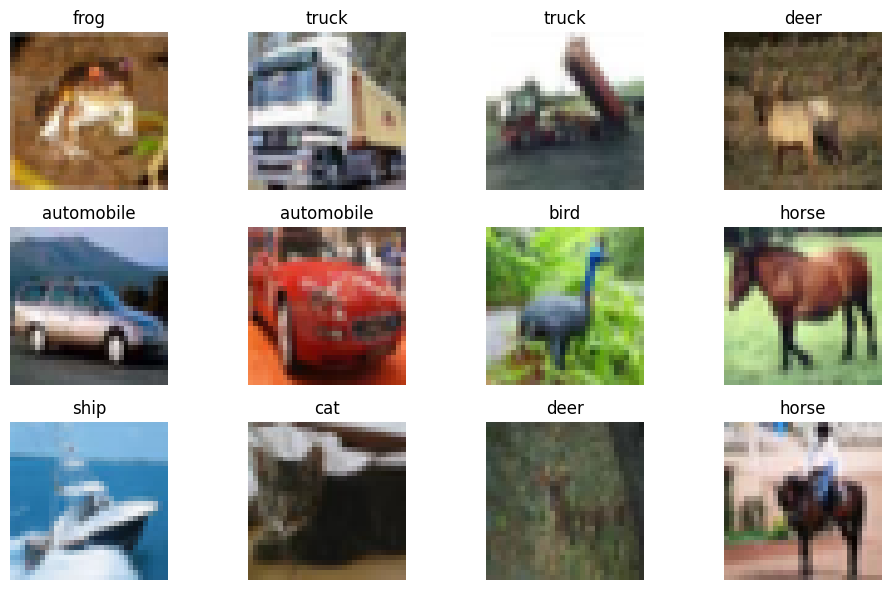

In [5]:
# Display sample images
plt.figure(figsize=(10, 6))
for i in range(12):
  plt.subplot(3, 4, i + 1)
  plt.imshow(X_train[i])
  plt.title(CATEGORIES[y_train[i][0]])
  plt.axis('off')
plt.tight_layout()
plt.show()

In [6]:
# Normalize pixel values from 0-255 to 0-1
X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0
print("Minimum pixel value:", X_train.min())
print("Maximum pixel value:", X_train.max())

Minimum pixel value: 0.0
Maximum pixel value: 1.0


In [8]:
# Convert class labels into categorical format
y_train = keras.utils.to_categorical(y_train, 10)
y_test = keras.utils.to_categorical(y_test, 10)
print("Training labels shape:", y_train.shape)
print("Testing labels shape:", y_test.shape)

Training labels shape: (50000, 10)
Testing labels shape: (10000, 10)


In [9]:
# Display final dataset shapes
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)
X_train: (50000, 32, 32, 3)
y_train: (50000, 10)
X_test: (10000, 32, 32, 3)
y_test: (10000, 10)

X_train: (50000, 32, 32, 3)
y_train: (50000, 10)
X_test: (10000, 32, 32, 3)
y_test: (10000, 10)


In [10]:
# Define CNN model
model = keras.Sequential([
keras.Input(shape=(32, 32, 3)),
# First convolution layer
layers.Conv2D(32, (3, 3), activation='relu'),
# First pooling layer
layers.MaxPooling2D((2, 2)),
# Second convolution layer
layers.Conv2D(64, (3, 3), activation='relu'),
# Second pooling layer
layers.MaxPooling2D((2, 2)),
# Convert feature maps into one-dimensional vector
layers.Flatten(),
# Fully connected layer
layers.Dense(128, activation='relu'),
# Output layer - 10 classes
layers.Dense(10, activation='softmax')
])
print("CNN model created successfully!")

CNN model created successfully!


In [12]:
# Display model architecture
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       295,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 315,722 (1.20 MB)

 Trainable params: 315,722 (1.20 MB)

 Non-trainable params: 0 (0.00 B)

In [13]:
# Compile the CNN model
model.compile(
optimizer='adam',
loss='categorical_crossentropy',
metrics=['accuracy']
)
print("Model compiled successfully!")


Model compiled successfully!


In [14]:
# Train the CNN model
history = model.fit(
X_train,
y_train,
epochs=10,
batch_size=64,
validation_split=0.1,
verbose=1
)


Epoch 1/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 62s 85ms/step - accuracy: 0.4585 - loss: 1.5032 - val_accuracy: 0.5754 - val_loss: 1.2184
Epoch 2/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 58s 82ms/step - accuracy: 0.6010 - loss: 1.1387 - val_accuracy: 0.6238 - val_loss: 1.0826
Epoch 3/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 58s 82ms/step - accuracy: 0.6526 - loss: 0.9978 - val_accuracy: 0.6470 - val_loss: 1.0248
Epoch 4/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 58s 82ms/step - accuracy: 0.6827 - loss: 0.9059 - val_accuracy: 0.6780 - val_loss: 0.9352
Epoch 5/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 58s 82ms/step - accuracy: 0.7148 - loss: 0.8226 - val_accuracy: 0.7016 - val_loss: 0.8751
Epoch 6/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 58s 82ms/step - accuracy: 0.7360 - loss: 0.7587 - val_accuracy: 0.6870 - val_loss: 0.9211
Epoch 7/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 59s 83ms/step - accuracy: 0.7574 - loss: 0.6993 - val_accuracy: 0.7110 - val_loss: 0.8634
Epoch 8/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 59s 83ms/step - accuracy: 0.7772 - loss: 0.6392 - 

In [15]:
# Evaluate the model on test data
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=1)
print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)
print("Test Accuracy Percentage:", test_accuracy * 100)


313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - accuracy: 0.6972 - loss: 0.9581
Test Loss: 0.9580948352813721
Test Accuracy: 0.6972000002861023
Test Accuracy Percentage: 69.72000002861023


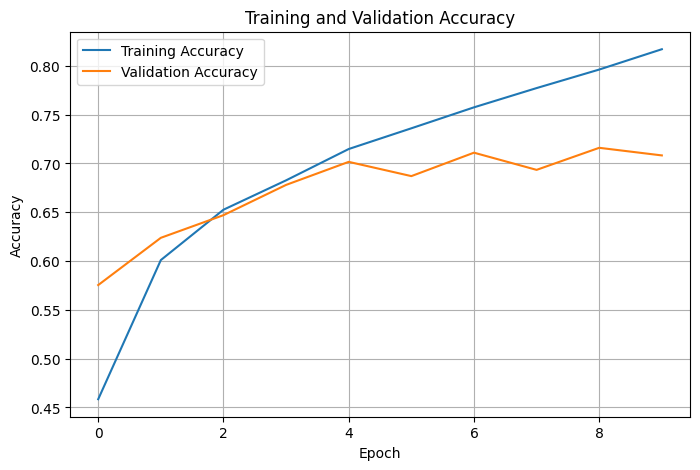

In [16]:
# Plot training and validation accuracy
plt.figure(figsize=(8, 5))
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid()
plt.show()

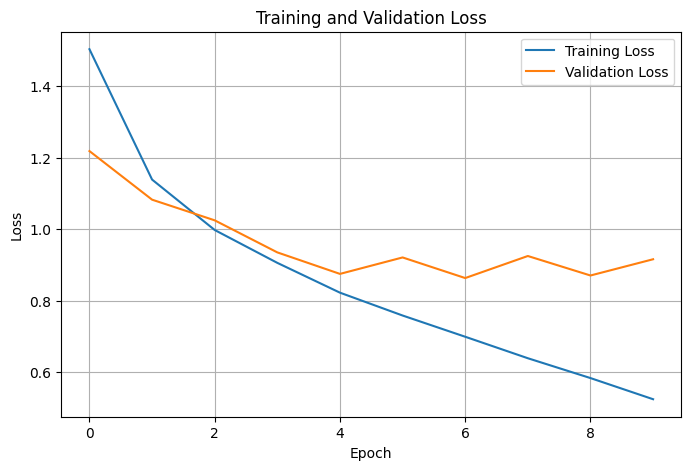

In [17]:
# Plot training and validation loss
plt.figure(figsize=(8, 5))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid()
plt.show()


In [18]:
# Make predictions on test images
predictions = model.predict(X_test)
print("Predictions generated successfully!")
print("Prediction shape:", predictions.shape)

313/313 ━━━━━━━━━━━━━━━━━━━━ 6s 18ms/step
Predictions generated successfully!
Prediction shape: (10000, 10)


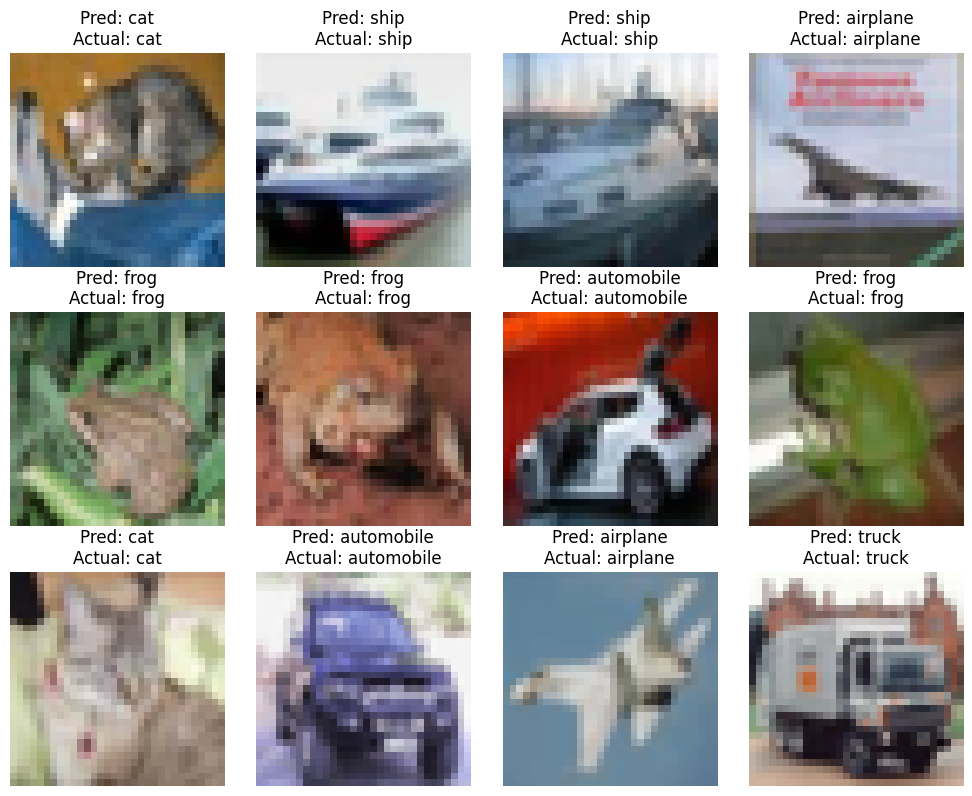

In [20]:
# Display predicted and actual classes
plt.figure(figsize=(10, 8))

for i in range(12):
    plt.subplot(3, 4, i + 1)
    plt.imshow(X_test[i])

    predicted_class = np.argmax(predictions[i])
    actual_class = np.argmax(y_test[i])
    plt.title(
        f"Pred: {CATEGORIES[predicted_class]}\n"
        f"Actual: {CATEGORIES[actual_class]}"
    )
    plt.axis('off')
plt.tight_layout()
plt.show()


In [21]:
# Calculate correct predictions
predicted_labels = np.argmax(predictions, axis=1)
actual_labels = np.argmax(y_test, axis=1)
correct_predictions = np.sum(predicted_labels == actual_labels)
total_predictions = len(actual_labels)
print("Correct Predictions:", correct_predictions)
print("Total Predictions:", total_predictions)
print("Accuracy:", correct_predictions / total_predictions * 100, "%")


Correct Predictions: 6972
Total Predictions: 10000
Accuracy: 69.72 %


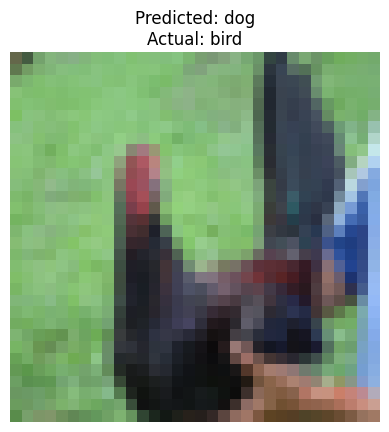

Predicted Class: dog
Actual Class: bird


In [25]:
# Test a single image
index = 25
image = X_test[index]
actual = np.argmax(y_test[index])
prediction = model.predict(np.expand_dims(image, axis=0), verbose=0)
predicted = np.argmax(prediction)
plt.imshow(image)
plt.title(
f"Predicted: {CATEGORIES[predicted]}\n"
f"Actual: {CATEGORIES[actual]}"
)
plt.axis('off')
plt.show()
print("Predicted Class:", CATEGORIES[predicted])
print("Actual Class:", CATEGORIES[actual])